## Machine Learning Lab - 6

### Name : Piyush Khokale

### Section : A-A2

### Roll no : 17

In [2]:
import pandas as pd 
import seaborn as sns 
import numpy as np 
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

In [3]:
df = pd.read_csv("seeds.csv")

In [4]:
df.head()

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)"
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1


In [5]:
df.isnull().sum()

Area                       0
Perimeter                  0
Compactness                0
Length of kernel           0
Width of kernel            0
Asymmetry coefficient      0
Length of kernel groove    0
Class (1, 2, 3)            0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df=df.drop_duplicates()

In [8]:
df.duplicated().sum()


np.int64(0)

In [9]:
X = df.drop("Class (1, 2, 3)", axis=1)
y_original = df["Class (1, 2, 3)"]

print("Input shape:", X.shape)
print("Output shape:", y_original.shape)

Input shape: (210, 7)
Output shape: (210,)


In [10]:
y = y_original - 1  # Convert to 0-based indexing

print("Original classes:")
print(sorted(y_original.unique()))

print("end")

Original classes:
[np.int64(1), np.int64(2), np.int64(3)]
end


In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)

print("Training sample :", X_train.shape, y_train.shape)
print("Testing sample :", X_test.shape, y_test.shape)

Training sample : (168, 7) (168,)
Testing sample : (42, 7) (42,)


In [12]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [13]:
scaler.fit_transform(X_test)

array([[-0.13481356, -0.30885661,  1.63834475, -0.72108928,  0.28326462,
        -0.76430253, -1.20943602],
       [-0.86696115, -0.79265998, -1.079508  , -0.44412568, -1.01611436,
        -0.08296069, -0.1493714 ],
       [ 0.3031065 ,  0.49244271, -0.70339658,  0.66153059,  0.00779627,
        -0.80711315,  0.9685525 ],
       [-1.32882996, -1.4578896 , -0.42131302, -1.40250766, -1.05769449,
         0.74059948, -0.71763216],
       [ 1.23710786,  1.05184035,  1.89804073,  0.79121989,  1.36954545,
        -0.66416923,  1.14006393],
       [-0.46667485, -0.42224803, -0.31833013, -0.17155833, -0.40280748,
         2.38191499,  0.06140168],
       [ 2.15058173,  2.0799225 ,  0.78313902,  2.07492419,  1.98285233,
         0.67094153,  1.87157051],
       [ 0.37495276,  0.31101645,  1.0697001 ,  0.12079214,  0.53534414,
         1.33559449, -0.56678476],
       [ 1.65107916,  1.67171341,  0.42941519,  1.6418938 ,  1.48908831,
        -0.57346877,  1.60087175],
       [ 1.28842662,  1.2257

In [14]:
model = Sequential([
    Input(shape=(7,)),
    Dense(16, activation='relu'),
    Dense(8, activation='relu'),
    Dense(3, activation='softmax')  # 3 classes
])

In [17]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 291 (1.14 KB)

 Trainable params: 291 (1.14 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
model.compile(optimizer=Adam(learning_rate=0.001), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [19]:
loss="sparse_categorical_crossentropy"

In [20]:
early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

In [21]:
history = model.fit(
    X_train_scaled, y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.0597 - loss: 1.2802 - val_accuracy: 0.0882 - val_loss: 1.2163
Epoch 2/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.1418 - loss: 1.1631 - val_accuracy: 0.3235 - val_loss: 1.0933
Epoch 3/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.2761 - loss: 1.0716 - val_accuracy: 0.4706 - val_loss: 0.9920
Epoch 4/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.3657 - loss: 1.0020 - val_accuracy: 0.5000 - val_loss: 0.9080
Epoch 5/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.4776 - loss: 0.9423 - val_accuracy: 0.6471 - val_loss: 0.8391
Epoch 6/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6119 - loss: 0.8927 - val_accuracy: 0.6765 - val_loss: 0.7774
Epoch 7/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7015 - loss: 0.8451 - val_accuracy: 0.7941 - val_loss: 0.7242
Epoch 8/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7463 - loss: 0.8014 - val_accuracy: 0.8529 - val_loss: 0.674

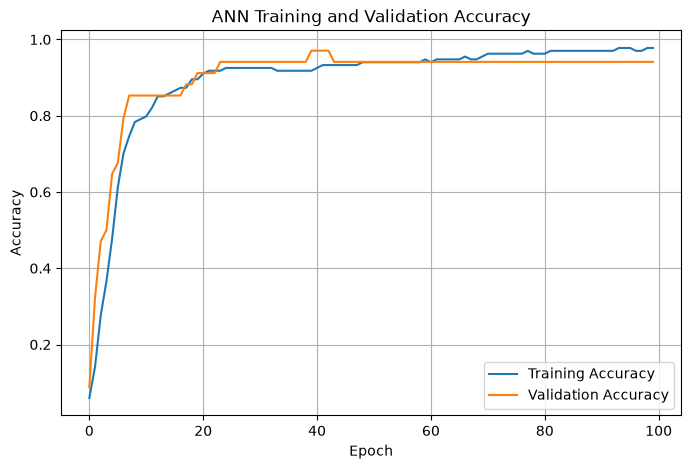

In [22]:
plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('ANN Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()

plt.show()

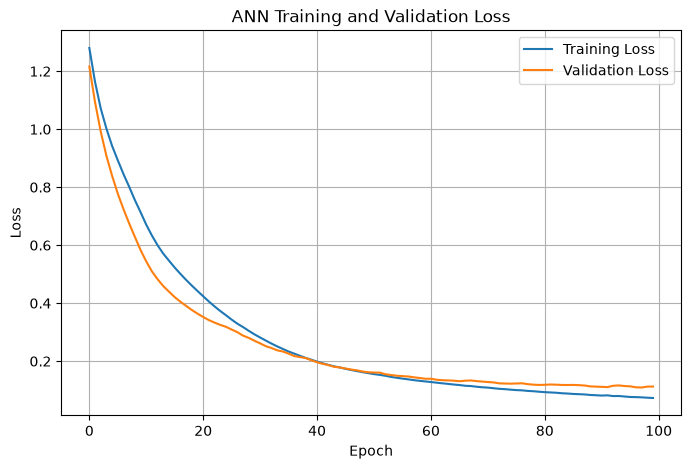

In [23]:
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('ANN Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()

In [24]:
test_loss, test_accuracy = model.evaluate(X_test_scaled, y_test, verbose=1)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8571 - loss: 0.3002
Test Loss: 0.3002
Test Accuracy: 0.8571


In [25]:
y_prob = model.predict(X_test_scaled,verbose=1)

print(y_prob[0:5])  # Display the first 5 predictions

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
[[9.78483796e-01 6.01468235e-03 1.55015178e-02]
 [2.35205814e-02 1.43617543e-03 9.75043237e-01]
 [5.05502105e-01 3.94302338e-01 1.00195564e-01]
 [2.82225024e-04 7.54237117e-05 9.99642372e-01]
 [1.39031457e-04 9.99660015e-01 2.00950715e-04]]


In [26]:
y_pred = np.argmax(y_prob, axis=1)

print("Predicted encoded cllasses:", y_pred[0:10])

Predicted encoded cllasses: [0 2 0 2 1 2 1 0 1 1]


In [27]:
y_pred_original = y_pred + 1
y_test_original = y_test + 1

print("Predicted classes:", y_pred_original[0:10])

Predicted classes: [1 3 1 3 2 3 2 1 2 2]


In [28]:
comparison = pd.DataFrame({'Actual class': y_test_original, 'Predicted class': y_pred_original})

comparison.head(15)

,Actual class,Predicted class
2,1,1
167,3,3
137,2,1
175,3,3
130,2,2
141,3,3
114,2,2
51,1,1
84,2,2
110,2,2


In [29]:
accuracy = accuracy_score(y_test_original, y_pred_original)
print(f"Accuracy: {accuracy:.4f}")

Accuracy: 0.8571


In [30]:
precision = precision_score(y_test_original, y_pred_original, average='weighted')
print(f"Precision: {precision:.4f}")


Precision: 0.8634


In [31]:
recall = recall_score(y_test_original, y_pred_original, average='weighted')
print(f"Recall: {recall:.4f}")

Recall: 0.8571


In [32]:
f1 = f1_score(y_test_original, y_pred_original, average='weighted')
print(f"F1 Score: {f1:.4f}")

F1 Score: 0.8499


In [34]:
metrics = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score'],
    'Value': [accuracy, precision, recall, f1]
})
metrics

,Metric,Value
0,Accuracy,0.857143
1,Precision,0.863399
2,Recall,0.857143
3,F1 Score,0.849926


In [35]:
print(classification_report(y_test_original, y_pred_original))

              precision    recall  f1-score   support

           1       0.90      0.64      0.75        14
           2       0.87      0.93      0.90        14
           3       0.82      1.00      0.90        14

    accuracy                           0.86        42
   macro avg       0.86      0.86      0.85        42
weighted avg       0.86      0.86      0.85        42



In [36]:
cm = confusion_matrix(y_test_original, y_pred_original)
print(cm)

[[ 9  2  3]
 [ 1 13  0]
 [ 0  0 14]]


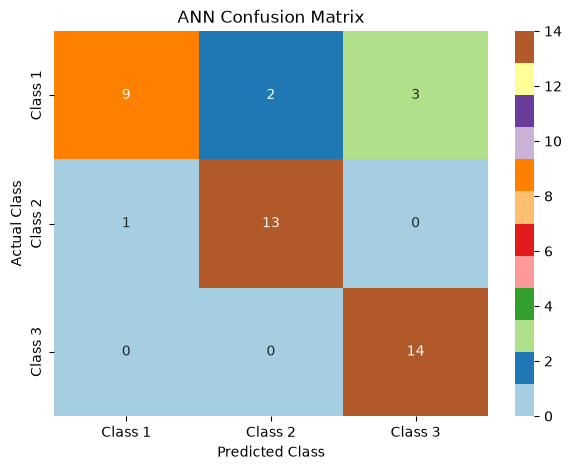

In [37]:
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d',cmap="Paired",xticklabels=["Class 1", "Class 2", "Class 3"], yticklabels=["Class 1", "Class 2", "Class 3"])

plt.title('ANN Confusion Matrix')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')

plt.show()

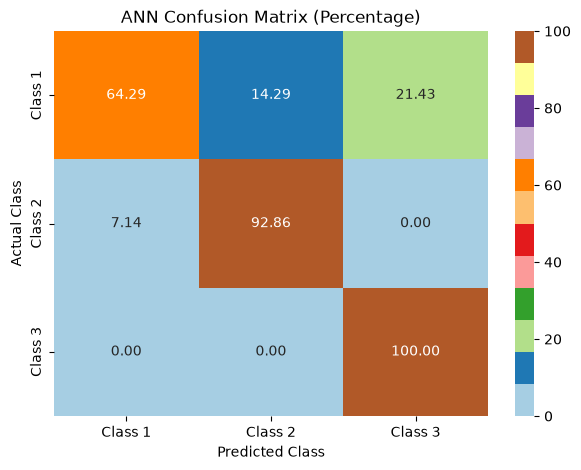

In [38]:
cm_percentage = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

plt.figure(figsize=(7, 5))
sns.heatmap(cm_percentage, annot=True, fmt='.2f', cmap="Paired",
            xticklabels=["Class 1", "Class 2", "Class 3"], yticklabels=["Class 1", "Class 2", "Class 3"])
plt.title('ANN Confusion Matrix (Percentage)')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.show()

In [40]:
def predict_new_seed(area, perimeter, compactness, length, width, asymmetry, groove):
    new_sample = pd.DataFrame([[area, perimeter, compactness, length, width, asymmetry, groove]],columns=X.columns)

In [42]:
area = float(input("Enter area: "))
perimeter = float(input("Enter perimeter: "))
compactness = float(input("Enter compactness: "))
length = float(input("Enter length of kernel: "))
width = float(input("Enter width of kernel: "))
asymmetry = float(input("Enter asymmetry coefficient: "))
groove = float(input("Enter length of kernel groove: "))

predict_new_seed(area, perimeter, compactness, length, width, asymmetry, groove)